# Free-cylinder resonant elasticity

## Problem and observations
Infer longitudinal stiffness **c11** and shear modulus **c44** from the measured resonance list of a commercial 4140 steel cylinder. Frequencies encode a volume elastic eigenproblem. Missing modes and degeneracies require correspondence inference. The available reference is an original-method fit, **not independently measured material truth**.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct,match_modes,objective
from src.physics_model import resonances
observed,weights=load_data(root/'data/raw_data.npz')
print('Positive source entries:',len(observed),'unique peak values:',len(np.unique(observed)))
print('Author analysis weights:',np.unique(weights,return_counts=True))

Positive source entries: 70 unique peak values: 43
Author analysis weights: (array([0. , 0.5, 1. ]), array([ 2,  1, 67]))


## Physics and selected method
The displacement solves $-\nabla\cdot(C:\varepsilon(u))=\rho\omega^2u$ with zero surface traction. Here rho is mass density, omega angular frequency and epsilon the symmetric strain. The isotropic tensor has Lamé coefficients lambda=c11-2c44 and mu=c44. A polynomial Rayleigh–Ritz discretization through total degree14 produces mass and stiffness matrices in eight symmetry blocks. Six rigid motions are removed.

The author used manual mode assignments. Here a disclosed monotone dynamic program replaces that manual stage using only observed frequencies and independent coarse steel priors. Original finite-difference LM, relative-error acceptance, damping and stopping conventions are preserved. Source assignments remain independent validation fixtures. Duplicate frequencies represent author's degenerate-mode multiplicities; weights express fitting preferences and are not instrument precision.

In [2]:
start=time.perf_counter()
fresh,diagnostics=reconstruct(observed,weights)
runtime=time.perf_counter()-start
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz') as data:
    upstream={k:data[k] for k in data.files}
indices=np.array(diagnostics['mode_indices'])
print('Fresh reconstruction seconds:',runtime)
print('Fresh c11,c44 [GPa]:',fresh['reconstruction'][0])
print('Reproduced original printed c11,c44 [GPa]:',upstream['reconstruction'][0])
print('Fresh weighted RMS [%]:',diagnostics['weighted_rms_percent'])
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
metrics,thresholds=judge.score(fresh,upstream,json.loads((root/'evaluation/metrics.json').read_text()),observed,weights)
for key,value in metrics.items():print(key,value,'<=',thresholds[key]['boundary'])
assert all(metrics[k]<=v['boundary'] for k,v in thresholds.items())

Fresh reconstruction seconds: 0.5104863999877125
Fresh c11,c44 [GPa]: [275.48482744  82.43676028]
Reproduced original printed c11,c44 [GPa]: [275.4848  82.4368]
Fresh weighted RMS [%]: 0.07748706979706296
c11_absolute_error_GPa 2.744158558698473e-05 <= 0.002
c44_absolute_error_GPa 3.9715735027812116e-05 <= 0.002
maximum_frequency_error_MHz 4.986352403202332e-08 <= 3e-06
observation_rms_percent 0.07748706979706296 <= 0.08523581


## Results: measured peaks, missing modes and residuals
Every positive supplied entry participates in correspondence inference. Missing placeholder zeros were removed during observation packaging; all calculated modes remain output quantities. The two zero-weight high-frequency entries are visible below even though they do not affect the original fit objective.

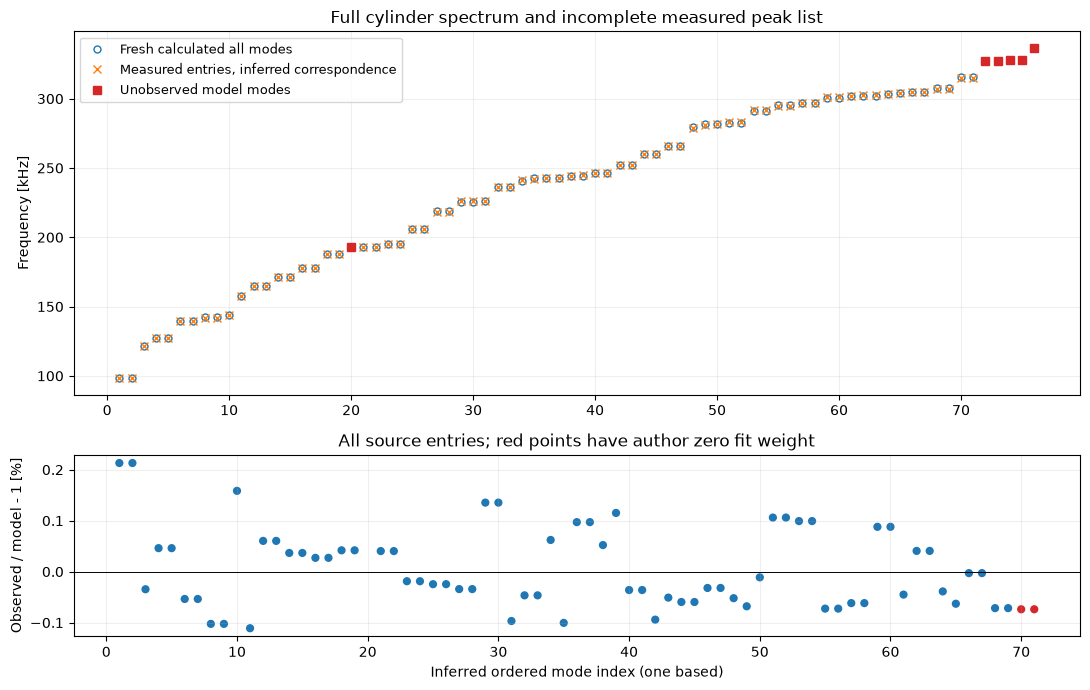

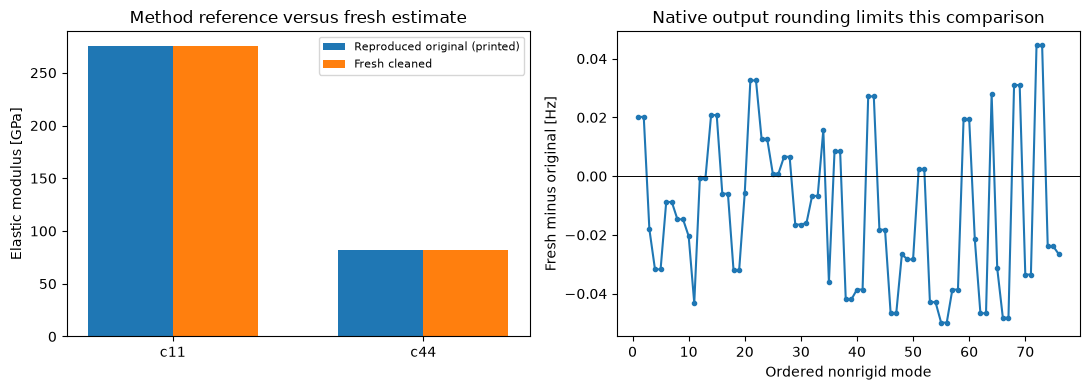

In [3]:
from src.visualization import review_figures
figures=review_figures(observed,weights,fresh,upstream,indices)
for figure in figures:display(figure)
plt.close('all')

## Discretization and initialization checks
Fresh calculations below compare polynomial orders8,10,12,14, preserving the paper's convergence question at this selected benchmark size. They do not claim to reproduce the manuscript's complete order20 study. Several coarse independent steel priors test correspondence stability; no manual mode label enters these reconstructions.

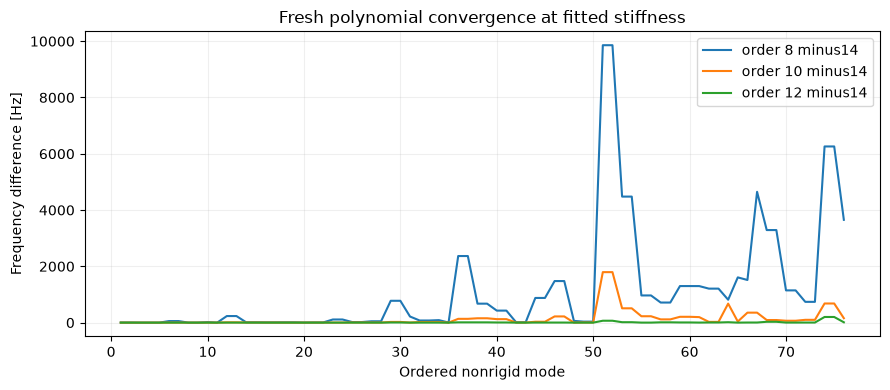

Initial [Mbar] -> fresh fitted [GPa]
(2.5, 0.7) [275.48482744  82.43676028]
(2.7, 0.8) [275.48482744  82.43676028]
(3.2, 0.95) [275.48482744  82.43676028]


In [4]:
orders=[8,10,12,14]
spectra=np.array([resonances(fresh['reconstruction'][0]/100,order) for order in orders])
fig,ax=plt.subplots(figsize=(9,4))
for order,spectrum in zip(orders[:-1],spectra[:-1]):ax.plot(np.arange(1,77),1e6*(spectrum-spectra[-1]),label=f'order {order} minus14')
ax.set(xlabel='Ordered nonrigid mode',ylabel='Frequency difference [Hz]',title='Fresh polynomial convergence at fitted stiffness')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();display(fig);plt.close(fig)
priors=[(2.5,.7),(2.7,.8),(3.2,.95)]
prior_results=[]
for prior in priors:
    result,detail=reconstruct(observed,weights,prior)
    assert np.array_equal(detail['mode_indices'],indices)
    prior_results.append(result['reconstruction'][0])
print('Initial [Mbar] -> fresh fitted [GPa]')
for prior,result in zip(priors,prior_results):print(prior,result)

## Local identifiability
The following grid evaluates the actual relative-frequency observation objective for fixed recovered correspondences. It is a fresh forward-model calculation, not a posterior uncertainty estimate. The elongated contours show stiffness tradeoffs.

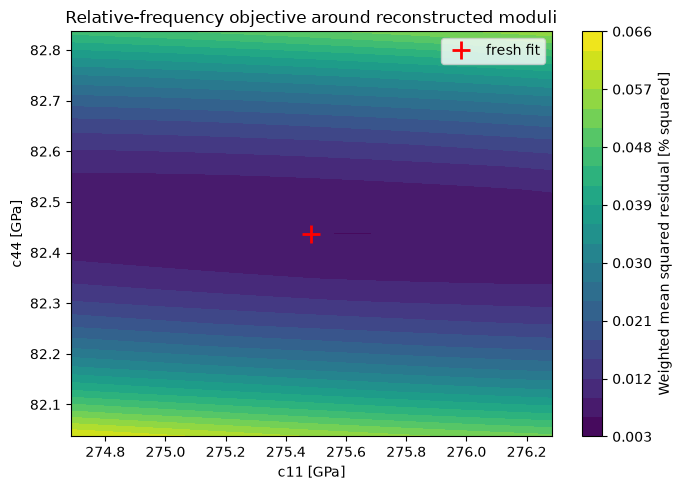

1258

In [5]:
center=fresh['reconstruction'][0]
xx=np.linspace(center[0]-.8,center[0]+.8,19);yy=np.linspace(center[1]-.4,center[1]+.4,19)
surface=np.array([[objective(observed,resonances([a/100,b/100])[indices],weights) for a in xx] for b in yy])
fig,ax=plt.subplots(figsize=(7,5))
contour=ax.contourf(xx,yy,surface,levels=20,cmap='viridis')
ax.plot(*center,'r+',ms=13,mew=2,label='fresh fit');ax.set(xlabel='c11 [GPa]',ylabel='c44 [GPa]',title='Relative-frequency objective around reconstructed moduli')
fig.colorbar(contour,ax=ax,label='Weighted mean squared residual [% squared]');ax.legend();fig.tight_layout();display(fig);plt.close(fig)
review={'runtime_s':runtime,'metrics':metrics,'moduli_GPa':center.tolist(),'priors_Mbar':priors,'prior_fits_GPa':np.array(prior_results).tolist(),'inferred_indices':indices.tolist()}
(root/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps(review,indent=2),encoding='utf8')

## Conclusion
The fresh cleaned method recovers the original full spectral fit within the predeclared numerical tolerances and satisfies the observed-frequency criterion. Coarse initial steel priors recover the same mode map. This establishes numerical reproduction of a selected method with explicit correspondence adaptation; it does not supply independent true elastic constants or experimental uncertainty. Finite polynomial order, isotropic material assumptions and author peak multiplicities remain scientific limitations.

References: Torres, Flores-Betancourt and Hermann, JASA151(2022), DOI10.1121/10.0011397; Balakirev et al., RSI90(2019), DOI10.1063/1.5123165. Full source/data hashes, original native exit1 and validation evidence are in the maintainer validation record.